# Le froid augmente-t-il les casses de canalisations d'eau potable ? ERA5 et casses réelles de Toronto

**Auteur : Alexandre Bignon**

## Question
Les casses de conduites d'eau potable sont-elles plus fréquentes quand il fait froid ? Ce notebook répond à cette question de bout en bout, sur des données réelles :

1. télécharger la température à 2 m de la réanalyse **ERA5** (Copernicus Climate Data Store) pour un point, sur toute la période étudiée ;
2. en tirer la température minimale de chaque jour ;
3. charger les casses de conduites de la Ville de Toronto (1990-2016) ;
4. relier le froid aux casses avec **deux méthodes** : d'abord la méthode par classes de température que j'ai utilisée pendant mon stage, puis une régression de Poisson pour aller plus loin ;
5. tester si le froid agit avec un décalage de quelques jours, et s'il agit au-delà de la simple saison ;
6. vérifier si les jours sont indépendants les uns des autres et, si ce n'est pas le cas, corriger les intervalles de confiance.

   
## Données
- **Température** : ERA5 (réanalyse du Copernicus Climate Data Store), jeu de données *ERA5 hourly time-series data on single levels*, point de Toronto, valeurs horaires de 1990 à 2016. C'est une réanalyse (maille d'environ 30 km), pas la mesure d'une station météo.
  *Generated using or contains modified Copernicus Climate Change Service information. Neither the European Commission nor ECMWF is responsible for any use that may be made of the Copernicus information or data it contains.*
- **Casses** : données ouvertes de la Ville de Toronto, une ligne par casse avec sa date (environ 35 000 casses de 1990 à 2016). Source : https://open.toronto.ca/dataset/watermain-breaks/ (les conditions d'utilisation sont indiquées sur cette page).



## Références
- Bruaset, S., & Sægrov, S. (2018). An analysis of the potential impact of climate change on the structural reliability of drinking water pipes in cold climate regions. *Water*, 10(4), 411. https://doi.org/10.3390/w10040411
- Copernicus Climate Change Service (2025) : *ERA5 hourly time-series data on single levels from 1940 to present*. Copernicus Climate Change Service (C3S) Climate Data Store (CDS). DOI : [10.24381/1cf1ad76](https://doi.org/10.24381/1cf1ad76) (consulté le 21-11-2026).
- Ville de Toronto, portail de données ouvertes, *Watermain Breaks* (consulté le 21-11-2026).

## 1. Paramètres

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import xarray as xr
import matplotlib.pyplot as plt
from scipy import stats
import statsmodels.api as sm
import statsmodels.formula.api as smf

In [2]:
# Point d'étude. Ici : Toronto
LAT, LON = 43.70, -79.38  
YEARS = range(1990, 2017)  # 1990 à 2016
DATA_DIR = Path("data")
DATA_DIR.mkdir(exist_ok=True)

In [3]:
casses = pd.read_excel("data/watermain-breaks-1990-to-2016-excel.xlsx")
print(casses.shape)
print(casses.columns.tolist())
print(casses.head())

(35465, 4)
['BREAK DATE', 'BREAK YEAR', 'X COORD', 'Y COORD']
  BREAK DATE  BREAK YEAR     X COORD      Y COORD
0 1990-01-01        1990  301316.434  4829245.578
1 1990-01-01        1990  326711.060  4846900.024
2 1990-01-01        1990  307098.866  4841152.120
3 1990-01-01        1990  306976.247  4842116.883
4 1990-01-01        1990  326543.178  4847968.844


## 2. Téléchargement de la température ERA5
La température à 2 m vient du jeu de données **ERA5 hourly time-series data on single levels** (identifiant `reanalysis-era5-single-levels-timeseries`) du Copernicus Climate Data Store. Ce jeu est conçu pour extraire **un point sur une longue période** : une seule requête suffit pour récupérer les valeurs **horaires** de 1990 à 2016 au point de Toronto (la maille ERA5 la plus proche, d'environ 30 km).

Pour l'utiliser, il faut :
- un compte gratuit sur le CDS, avec les conditions d'utilisation du jeu de données acceptées ;
- un fichier `~/.cdsapirc` contenant l'adresse de l'API et ma clé personnelle (voir le README). La clé ne doit jamais apparaître dans le notebook.

Le fichier est enregistré dans `data/`. Si le fichier existe déjà, la cellule ne retélécharge rien : on peut la relancer sans refaire la requête. Le téléchargement prend de quelques minutes à quelques dizaines de minutes, selon la file d'attente du CDS.

In [4]:
import cdsapi
import zipfile

cible = DATA_DIR / "era5_point_t2m_toronto.nc"

if not cible.exists():
    client = cdsapi.Client()
    client.retrieve(
        "reanalysis-era5-single-levels-timeseries",
        {
            "variable": ["2m_temperature"],
            "date": [f"{YEARS[0]}-01-01", f"{YEARS[-1]}-12-31"],
            "location": {"longitude": LON, "latitude": LAT},
            "data_format": "netcdf",
        },
        str(cible),
    )

# Si le CDS a renvoyé une archive zip, on l'ouvre
if zipfile.is_zipfile(cible):
    zip_path = cible.with_suffix(".zip")
    cible.rename(zip_path)
    with zipfile.ZipFile(zip_path) as z:
        z.extract(z.namelist()[0], DATA_DIR)
        (DATA_DIR / z.namelist()[0]).rename(cible)

print("Fichier prêt :", cible.exists())

Fichier prêt : True


## 3. Chargement et température minimale journalière
Le fichier ERA5 contient la température à 2 m au point de Toronto, **heure par heure** de 1990 à 2016, en **kelvins**. Je le charge, je convertis en °C (en retirant 273,15), puis je garde **le minimum de chaque jour**, car c'est la température sur laquelle reposent les deux méthodes.

*Limite :* ERA5 est une réanalyse (maille d'environ 30 km). Son minimum journalier, calculé à partir de valeurs horaires, est plus lissé que celui d'une station météo : il sous-estime un peu les nuits les plus froides. Un décalage constant ne changerait pas les pentes mesurées, mais un lissage plus fort pour les nuits les plus froides peut les modifier légèrement.

In [5]:
# On ouvre le fichier téléchargé (cible est défini dans la cellule de téléchargement)
ds = xr.open_dataset(cible)

# t2m = température à 2 m, nom court de la variable dans le fichier
t2m = ds["t2m"]

# Certains fichiers ERA5 ont une dimension en plus (expver, number) : on la fusionne par une moyenne
for dim in ("expver", "number"):
    if dim in t2m.dims:
        t2m = t2m.mean(dim)

# On retire les dimensions de taille 1 (il n'y a qu'un point, donc latitude et longitude disparaissent)
t2m = t2m.squeeze(drop=True)

# Le temps s'appelle valid_time dans les fichiers récents : on le renomme time, et on passe de kelvins en °C
nom_temps = "valid_time" if "valid_time" in t2m.coords else "time"
t2m = t2m.rename({nom_temps: "time"}) - 273.15

# Une ligne par jour : resample("1D") regroupe les 24 valeurs horaires de chaque jour, .min() garde la plus basse
jour = pd.DataFrame({
    "tmin": t2m.resample(time="1D").min().to_series(),
})
jour.index.name = "date"

ds.close()   # libère le fichier (sous Windows, ça évite qu'il reste verrouillé)
jour.head()

,tmin
date,
1990-01-01,-3.651825
1990-01-02,-4.171417
1990-01-03,-3.449005
1990-01-04,2.951935
1990-01-05,-3.303070


In [6]:
print(jour.index.min(), "→", jour.index.max(), "|", len(jour), "jours")

1990-01-01 00:00:00 → 2016-12-31 00:00:00 | 9862 jours


## 4. Construction du tableau jour par jour
Je regroupe les casses par date pour obtenir, pour chaque jour de 1990 à 2016, **deux informations** : la température minimale ERA5 et le nombre de casses signalées ce jour-là (0 s'il n'y en a pas eu). Ce tableau est la base des deux méthodes.

J'ajoute aussi deux colonnes : la **classe de température** (tranche de 1 °C, pour la méthode 2) et **l'année** (pour tenir compte de la baisse générale des casses au fil du temps dans la méthode 1).

Avant de construire le tableau, je vérifie que le fichier de casses du portail open.toronto.ca est exploitable : dates lisibles, cohérence entre la date et l'année indiquée.

In [7]:
# --- Dates des casses ---
casses["date"] = pd.to_datetime(casses["BREAK DATE"], dayfirst=True, errors="coerce")
print("Lignes :", len(casses), "| dates illisibles :", casses["date"].isna().sum())
print("Cohérence avec BREAK YEAR :", (casses["date"].dt.year == casses["BREAK YEAR"]).mean())

# Contrôle : nombre moyen de casses pour chaque mois de l'année (1 = janvier ... 12 = décembre)
# On divise par 27, le nombre d'années. On doit voir un pic en hiver.
casses_par_mois = casses["date"].dt.month.value_counts().sort_index()
print((casses_par_mois / 27).round(0))

# --- Un tableau avec une ligne par jour ---
# On récupère les dates de casse, sans l'heure
dates_casses = casses["date"].dropna().dt.normalize()

# value_counts() compte combien de fois chaque date apparaît = nombre de casses ce jour-là
casses_par_jour = dates_casses.value_counts()

# On part du tableau 'jour' (une ligne par jour) et on garde la température minimale
tableau = jour[["tmin"]].copy()

# On ajoute les casses : pandas les place sur la ligne de la même date
tableau["casses"] = casses_par_jour

# Les jours sans casse n'ont pas de valeur : on met 0
tableau["casses"] = tableau["casses"].fillna(0)

# On garde la période de la base de casses
tableau = tableau.loc["1990":"2016"]

# Classe de température : np.floor arrondit vers le bas (-4,3 devient -5 ; 2,7 devient 2)
tableau["classe"] = np.floor(tableau["tmin"]).astype(int)

# Année, comptée à partir de 1990 (0 pour 1990, 26 pour 2016)
tableau["annee"] = tableau.index.year - 1990

# --- Contrôles ---
print("Casses dans le tableau :", int(tableau["casses"].sum()), "sur", len(casses))
print("Jours :", len(tableau), "| jours avec au moins une casse :", (tableau["casses"] > 0).sum())
tableau.head()

Lignes : 35465 | dates illisibles : 0
Cohérence avec BREAK YEAR : 0.9997462286761596
date
1     273.0
2     221.0
3     131.0
4      54.0
5      40.0
6      49.0
7      55.0
8      61.0
9      69.0
10     77.0
11    104.0
12    180.0
Name: count, dtype: float64
Casses dans le tableau : 35465 sur 35465
Jours : 9862 | jours avec au moins une casse : 8219


,tmin,casses,classe,annee
date,,,,
1990-01-01,-3.651825,29.0,-4,0
1990-01-02,-4.171417,16.0,-5,0
1990-01-03,-3.449005,19.0,-4,0
1990-01-04,2.951935,12.0,2,0
1990-01-05,-3.303070,12.0,-4,0


## 5. Lien entre le froid et les casses
Je commence par reproduire la méthode de mon stage (méthode 1), puis je la complète avec un modèle de comptage plus fin (méthode 2).

### Méthode 1 : le taux de casse par classe de température (méthode de mon stage)
Cette méthode est celle que j'ai utilisée pendant mon stage sur un réseau d'eau potable en France. Elle s'inspire de l'étude de Bruaset et Sægrov (2018), réalisée en Norvège, qui utilise la température moyenne du jour pour caractériser la casse. J'ai retenu la **température minimale journalière**, qui représente mieux les conditions extrêmes.

Pendant mon stage, les données fournissaient la date de **réparation** de chaque casse, pas celle de la casse. Je supposais que les casses étaient réparées dans les 7 jours suivant l'événement, et j'associais donc à chaque casse la température minimale la plus basse des **7 jours précédant la réparation**.

**Principe**
1. On travaille jour par jour, avec la température minimale du jour.
2. On range chaque jour dans une classe de 1 °C (par exemple de -5 à -4 °C).
3. Pour chaque classe, on calcule le taux de casse :

   taux de casse = nombre de casses dans la classe / nombre de jours passés dans cette classe

   Diviser par le nombre de jours est essentiel : une température fréquente aurait plus de casses uniquement parce qu'elle revient plus souvent. Le taux compare les températures à égalité d'exposition.
4. On écarte les classes trop rares (moins de jours que la moyenne moins l'écart type), car leur taux est peu fiable.
5. On fait une régression linéaire (OLS) : taux de casse = α + β × température. Un β négatif veut dire que le taux de casse augmente quand la température baisse.
6. On teste l'hypothèse « β = 0 » (le froid n'a aucun effet). Si la p-value est inférieure à 0,05, on la rejette. Le R² donne la part des variations du taux de casse expliquée par la température.

**Données de Toronto :** d'après la documentation du jeu de données, `BREAK DATE` est la date à laquelle la casse a été **signalée**, et non forcément celle de la casse elle-même. J'associe chaque casse à la température du jour du signalement, sans la correction des 7 jours de mon stage, et j'examine plus loin, avec un test de décalage, si le froid agit avec quelques jours de retard. Le fichier ne contient pas non plus de colonne de matériau : toutes les conduites sont analysées ensemble.

Moyenne : 182.6 jours, écart type : 134.0 jours
Seuil : 49 jours | classes gardées : 40 sur 54
Tc = 4.764 + (-0.2166) × Tmin   R² = 0.84   p = 1.6e-16
Pente : -0.2166  (IC 95 % : -0.2480 à -0.1851)


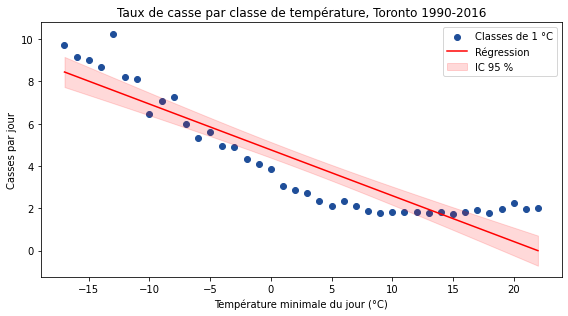

In [8]:
# ============ 1. LE TAUX DE CASSE DE CHAQUE CLASSE ============
# Liste des classes présentes, de la plus froide à la plus chaude
liste_classes = sorted(tableau["classe"].unique())

resultats = []   # on y mettra une ligne par classe

for t in liste_classes:
    # Les jours dont la température minimale est dans la classe t
    jours_de_la_classe = tableau[tableau["classe"] == t]

    nb_jours = len(jours_de_la_classe)                 # nombre de jours dans la classe
    nb_casses = jours_de_la_classe["casses"].sum()     # nombre de casses ces jours-là
    taux = nb_casses / nb_jours                        # casses par jour

    resultats.append([t, nb_jours, nb_casses, taux])

# On transforme la liste en tableau
classes = pd.DataFrame(resultats, columns=["classe", "jours", "casses", "taux"])


# ============ 2. LE TRI DES CLASSES TROP RARES ============
moyenne_jours = classes["jours"].mean()        # nombre moyen de jours par classe
ecart_type_jours = classes["jours"].std()      # dispersion de ces nombres de jours

# On exclut les classes qui ont moins de jours que (moyenne - écart type)
seuil = moyenne_jours - ecart_type_jours
classes_fiables = classes[classes["jours"] >= seuil]

print(f"Moyenne : {moyenne_jours:.1f} jours, écart type : {ecart_type_jours:.1f} jours")
print(f"Seuil : {seuil:.0f} jours | classes gardées : {len(classes_fiables)} sur {len(classes)}")


# ============ 3. LA RÉGRESSION LINÉAIRE ============
x = classes_fiables["classe"]    # température minimale (en °C)
y = classes_fiables["taux"]      # taux de casse (casses par jour)

reg = stats.linregress(x, y)     # droite : taux = intercept + pente × température

print(f"Tc = {reg.intercept:.3f} + ({reg.slope:.4f}) × Tmin   R² = {reg.rvalue**2:.2f}   p = {reg.pvalue:.1e}")

# Intervalle de confiance à 95 % de la pente
t_crit = stats.t.ppf(0.975, len(x) - 2)
bas = reg.slope - t_crit * reg.stderr
haut = reg.slope + t_crit * reg.stderr
print(f"Pente : {reg.slope:.4f}  (IC 95 % : {bas:.4f} à {haut:.4f})")


# ============ 4. LE GRAPHIQUE ============
fig, ax = plt.subplots(figsize=(8, 4.5))
ax.scatter(x, y, color="#1f4e99", label="Classes de 1 °C")            # un point par classe
ax.plot(x, reg.intercept + reg.slope * x, "r-", label="Régression")   # la droite

# Bande d'incertitude à 95 % (même régression, refaite avec statsmodels)
modele_ols = sm.OLS(y, sm.add_constant(x)).fit()
x_ligne = np.linspace(x.min(), x.max(), 100)
bande = modele_ols.get_prediction(sm.add_constant(x_ligne)).summary_frame(alpha=0.05)
ax.fill_between(x_ligne, bande["mean_ci_lower"], bande["mean_ci_upper"],
                color="red", alpha=0.15, label="IC 95 %")

ax.set_xlabel("Température minimale du jour (°C)")
ax.set_ylabel("Casses par jour")
ax.set_title("Taux de casse par classe de température, Toronto 1990-2016")
ax.legend()
plt.tight_layout()
plt.show()

### Conclusion de la méthode 1
Après le tri (40 classes gardées sur 54, seuil de 49 jours) :

**taux de casse = 4,76 − 0,217 × température minimale**, avec **R² = 0,84** et **p = 1,6 × 10⁻¹⁶**.

- **Pente :** chaque degré de moins ajoute environ 0,22 casse par jour sur le réseau. Le taux passe d'environ 0,4 casse par jour à +20 °C à environ 9 casses par jour à -20 °C.
- **Significativité :** la probabilité d'obtenir une telle pente par hasard, si le froid n'avait aucun effet, est quasi nulle.

**Limites :**
- Le R² porte sur 40 moyennes par classe, pas sur chaque jour : faire des moyennes réduit le bruit, donc il est plus élevé que si on prédisait la casse jour par jour.
- La droite n'est valable que dans la plage de températures observée : au-delà de +22 °C elle donnerait un taux négatif, ce qui est impossible.
- ERA5 est une réanalyse lissée, et il s'agit d'une corrélation : le matériau, l'âge des conduites et le sol ne sont pas pris en compte.
- Il s'agit d'une corrélation. Le fichier de Toronto ne contient ni le matériau ni le diamètre des conduites, alors que ces facteurs jouent beaucoup : pendant mon stage, j'ai séparé les conduites par matériau et par diamètre. L'âge des conduites, le sol et la pression ne sont pas pris en compte non plus.

### Méthode 2 : la régression de Poisson jour par jour
Pour aller plus loin que la méthode de mon stage, je modélise directement le **nombre de casses de chaque jour** avec une régression de Poisson, adaptée aux comptages (entiers positifs). Elle diffère de la méthode 1 sur plusieurs points :
- elle utilise la **température minimale exacte** de chaque jour (environ 9 800 jours), sans regroupement en classes ;
- elle suppose un effet **multiplicatif** : chaque degré de moins multiplie le nombre de casses par le même facteur, d'où un résultat en pourcentage ;
- elle permet d'ajouter d'autres variables (l'année, la saison) et de comparer des modèles avec l'AIC, ce que la méthode 1 ne permet pas.

On ajoute l'année dans le modèle pour tenir compte de la baisse générale des casses au fil du temps.

['tmin', 'casses', 'classe', 'annee']
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
const          1.6191      0.016    101.025      0.000       1.588       1.651
tmin          -0.0563      0.001    -66.671      0.000      -0.058      -0.055
annee         -0.0202      0.001    -17.794      0.000      -0.022      -0.018

Effet : +5.79 % de casses par °C de moins (IC 95 % : +5.62 à +5.97 %)


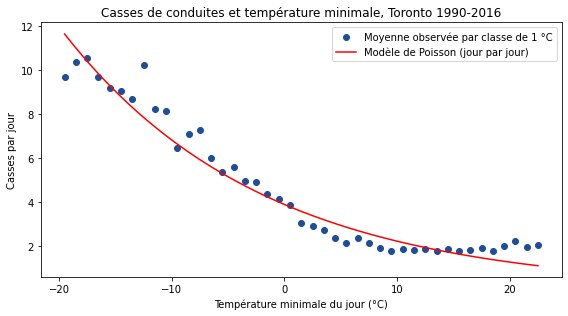

In [9]:
print(tableau.columns.tolist())
# add_constant ajoute une colonne de 1 : c'est le niveau de casses de départ (la constante du modèle).
X = sm.add_constant(tableau[["tmin", "annee"]])

# GLM = modèle linéaire généralisé. family=Poisson : on modélise un nombre de casses (entier positif).
# scale="X2" corrige les intervalles de confiance : les écarts réels entre jours sont plus grands que ceux que suppose le modèle de Poisson,
# et sans cette correction les intervalles seraient trop étroits.
modele = sm.GLM(tableau["casses"], X, family=sm.families.Poisson()).fit(scale="X2")
print(modele.summary().tables[1])

# --- Lecture de l'effet du froid ---
b = modele.params["tmin"]            # coefficient de la température
ic = modele.conf_int().loc["tmin"]   # son intervalle de confiance à 95 %

# Le coefficient est sur une échelle logarithmique : exp(coefficient) - 1 donne un pourcentage.
# Il est négatif (plus chaud = moins de casses), donc on prend son opposé pour exprimer l'effet d'un degré de moins.
print(f"\nEffet : {(np.exp(-b)-1)*100:+.2f} % de casses par °C de moins "
      f"(IC 95 % : {(np.exp(-ic[1])-1)*100:+.2f} à {(np.exp(-ic[0])-1)*100:+.2f} %)")

# --- Graphique : moyennes observées par classe de température + courbe du modèle ---
# 9 800 points seraient illisibles : on affiche la moyenne de casses par jour pour chaque classe de 1 °C.
temp_points = []
casses_points = []
for t in sorted(tableau["classe"].unique()):
    jours_classe = tableau[tableau["classe"] == t]    # les jours de cette classe
    if len(jours_classe) >= 30:                       # on masque les classes très rares (affichage seulement)
        temp_points.append(t + 0.5)                   # milieu de la classe
        casses_points.append(jours_classe["casses"].mean())

# Courbe du modèle : exp(constante + coefficient_tmin × température + coefficient_annee × année moyenne)
t_ligne = np.linspace(min(temp_points), max(temp_points), 100)
courbe = np.exp(modele.params["const"] + b * t_ligne
                + modele.params["annee"] * tableau["annee"].mean())

fig, ax = plt.subplots(figsize=(8, 4.5))
ax.scatter(temp_points, casses_points, color="#1f4e99", label="Moyenne observée par classe de 1 °C")
ax.plot(t_ligne, courbe, "r-", label="Modèle de Poisson (jour par jour)")
ax.set_xlabel("Température minimale du jour (°C)")
ax.set_ylabel("Casses par jour")
ax.set_title("Casses de conduites et température minimale, Toronto 1990-2016")
ax.legend()
plt.tight_layout()
plt.show()

### Conclusion de la méthode 2
Sur le graphique, chaque point est la moyenne de casses par jour pour une classe de température de 1 °C, et la courbe rouge est ce que le modèle attend. Plus la température baisse, plus les points sont hauts, et la courbe suit cette tendance.

Le modèle chiffre ce lien : **+5,79 % de casses par °C de moins** (intervalle de confiance à 95 % : +5,62 à +5,97 %, p < 0,001). Dix degrés de moins correspondent à environ 76 % de casses en plus, et vingt degrés de moins à environ trois fois plus de casses. À température égale, le nombre de casses baisse d'environ 2 % par an, ce qui montre l'intérêt d'avoir ajouté l'année dans le modèle.

Par rapport à la méthode 1, ce modèle utilise chaque jour tel quel (environ 9 800 jours) et la température exacte, sans regroupement en classes. Il donne un effet en pourcentage, plus facile à comparer d'un réseau à l'autre.

**Limites :**
- Le modèle suppose que l'effet du froid est multiplicatif (même pourcentage à chaque degré), ce qui donne une courbe exponentielle. Si la vraie relation a une autre forme, l'ajustement peut s'en écarter aux températures extrêmes.
- La température suit en partie la saison : une partie du lien peut venir de l'hiver en général. C'est ce que je teste plus loin.
- Il s'agit d'une corrélation : le fichier de Toronto ne contient ni le matériau ni le diamètre des conduites, et l'âge, le sol et la pression ne sont pas pris en compte. ERA5 est aussi une réanalyse lissée.

## 6. Le froid agit-il tout de suite, ou avec un décalage ?
Le gel peut provoquer des casses après l'épisode de froid, par exemple parce que le sol dégèle ou parce qu'une conduite fragilisée cède plus tard. De plus, la date enregistrée dans la base peut suivre la casse de quelques jours. Je teste donc un décalage de 0 à 7 jours entre la casse et la température : la casse du jour *d* est associée à la température minimale du jour *d − k*, avec *k* entre 0 et 7.

Je le fais pour chacune des deux méthodes.

### Avec la méthode 1 (classes de température)
Pour chaque décalage, je refais tout le calcul (classes, taux de casse, tri, droite) et je note le R² et la pente.

In [10]:
print("Décalage (jours) |  R²  | pente")

for decalage in range(0, 8):
    # Température minimale d'il y a 'decalage' jours (0 = le jour même)
    t_decalee = tableau["tmin"].shift(decalage)
    t_classe = np.floor(t_decalee)                      # sa classe de 1 °C

    liste = []
    for t in sorted(t_classe.dropna().unique()):
        masque = t_classe == t                          # True pour les jours de cette classe
        nb_jours = masque.sum()
        nb_casses = tableau["casses"][masque].sum()
        liste.append([t, nb_jours, nb_casses / nb_jours])

    c = pd.DataFrame(liste, columns=["classe", "jours", "taux"])
    c = c[c["jours"] >= c["jours"].mean() - c["jours"].std()]    # même tri qu'avant

    r = stats.linregress(c["classe"], c["taux"])
    print(f"{decalage:>10}       | {r.rvalue**2:.2f} | {r.slope:.4f}")

Décalage (jours) |  R²  | pente
         0       | 0.84 | -0.2166
         1       | 0.84 | -0.2205
         2       | 0.84 | -0.2197
         3       | 0.83 | -0.2246
         4       | 0.83 | -0.2205
         5       | 0.83 | -0.2196
         6       | 0.83 | -0.2173
         7       | 0.83 | -0.2194


Le R² reste entre 0,83 et 0,84 et la pente entre -0,217 et -0,225 casse par jour et par °C, quel que soit le décalage. La relation entre le froid et le taux de casse est donc **stable** : elle ne dépend pas du décalage choisi. En revanche, cette méthode, qui fait des moyennes par classe, ne permet pas de départager les décalages.

### Avec la méthode 2 (Poisson jour par jour)
Pour départager les décalages, j'utilise l'**AIC** (critère d'information d'Akaike). C'est une note qui compare des modèles ajustés sur les **mêmes données** : plus elle est basse, mieux le modèle explique les casses, en pénalisant les modèles trop compliqués. Seul l'écart entre deux AIC compte, et un écart de plus de 10 est net.

Ici, tous les modèles expliquent les casses des **mêmes jours** (j'ai retiré les 7 premiers jours de 1990, qui n'ont pas de température décalée complète) : seule la température associée change (celle d'il y a 0 à 7 jours). La comparaison est donc valable. Elle ne l'est pas pour la méthode 1, où chaque décalage change les classes et les taux eux-mêmes.

In [11]:
base = tableau.iloc[7:].copy()

print("Décalage (jours) | AIC")

# On teste 8 décalages : 0 (le jour même), 1, 2, ... jusqu'à 7 jours avant
for decalage in range(0, 8):

    # shift(decalage) fait descendre la colonne tmin de 'decalage' lignes :
    # .loc[base.index] ne garde que les jours de 'base'.
    base["tmin_decalee"] = tableau["tmin"].shift(decalage).loc[base.index]

    X = sm.add_constant(base[["tmin_decalee"]])
    modele = sm.GLM(base["casses"], X, family=sm.families.Poisson()).fit()

    # .aic donne la note du modèle : plus elle est basse, mieux il explique les casses
    print(f"{decalage:>10}       | {modele.aic:.1f}")

Décalage (jours) | AIC
         0       | 50490.1
         1       | 50391.3
         2       | 50195.5
         3       | 49845.3
         4       | 49921.2
         5       | 50234.6
         6       | 50664.4
         7       | 51088.3


Le meilleur modèle est celui avec la température d'il y a **3 jours** (AIC de 49 845), loin devant le décalage nul (50 490) et le décalage de 4 jours (49 921). Les casses d'un jour sont donc mieux expliquées par le froid de quelques jours auparavant que par celui du jour même.

**Interprétation prudente :** ce retard peut venir du froid lui-même (le gel du sol agit avec du retard) ou de la date enregistrée dans la base, qui est, d'après la documentation du jeu de données, la date de signalement de la casse et peut donc la suivre de quelques jours. Les données ne permettent pas de trancher entre ces deux explications.

## 7. Est-ce vraiment le froid, ou simplement la saison ?
Le froid et l'hiver vont ensemble : les jours les plus froids sont presque tous en décembre, janvier et février. Le lien trouvé plus haut peut donc venir en partie de l'hiver en général (sol détrempé ou gelé, variations de pression dans le réseau, etc.), et pas seulement de la température.

Pour le tester, j'ajoute le **mois de l'année** au modèle de Poisson. Chaque mois a alors son propre niveau de casses, et le modèle compare des jours **d'un même mois** entre eux : un jour très froid de janvier contre un jour plus doux du même mois. Si l'effet de la température reste net, il ne vient pas seulement de la saison.

In [12]:
# Le mois de chaque jour (1 = janvier, ..., 12 = décembre), à partir de la date
tableau["mois"] = tableau.index.month

# Modèle sans la saison : les casses expliquées par la température minimale et l'année.
# La formule "casses ~ tmin + annee" se lit : « casses expliquées par tmin et annee ».
m_sans = smf.glm("casses ~ tmin + annee", data=tableau,
                 family=sm.families.Poisson()).fit(cov_type="HAC", cov_kwds={"maxlags": 30})
m_avec = smf.glm("casses ~ tmin + annee + C(mois)", data=tableau,
                 family=sm.families.Poisson()).fit(cov_type="HAC", cov_kwds={"maxlags": 30})

# On affiche l'effet de la température dans chacun des deux modèles
for nom, m in [("Sans saison", m_sans), ("Avec saison", m_avec)]:
    coef = m.params["tmin"]                 # coefficient de la température
    ic_m = m.conf_int().loc["tmin"]         # son intervalle de confiance à 95 %
    # exp(-coefficient) - 1 donne le pourcentage de casses en plus pour 1 °C de moins
    print(f"{nom} : {(np.exp(-coef)-1)*100:+.2f} % par °C de moins "
          f"(IC 95 % : {(np.exp(-ic_m[1])-1)*100:+.2f} à {(np.exp(-ic_m[0])-1)*100:+.2f} %)")

Sans saison : +5.79 % par °C de moins (IC 95 % : +5.41 à +6.17 %)
Avec saison : +3.02 % par °C de moins (IC 95 % : +2.54 à +3.50 %)


### Conclusion : froid ou saison ?
Sans tenir compte de la saison, le modèle trouve **+5,79 % de casses par °C de moins** (intervalle de confiance à 95 % : +5,62 à +5,97 %). En comparant des jours d'un même mois, l'effet tombe à **+3,02 % par °C de moins** (IC 95 % : +2,73 à +3,31 %).

Deux enseignements :
- **Environ la moitié du lien observé vient de la saison en général** : les deux intervalles ne se chevauchent pas, donc la baisse est nette. Ce qui fait la différence entre un hiver et un été (sol, demande en eau, etc.) pèse autant que la température elle-même.
- **Le froid garde pourtant un effet propre et significatif** : au sein d'un même mois, les jours les plus froids comptent plus de casses que les jours plus doux. À titre d'exemple, deux jours du même mois séparés de 12 °C correspondent à environ 43 % de casses en plus pour le plus froid.

**Limite :** le modèle suppose que l'effet du froid est le même chaque mois, et il s'agit toujours d'une corrélation : le matériau, l'âge des conduites et le sol ne sont pas dans les données.

## 8. Les jours sont-ils indépendants ?
Mes modèles supposent que chaque jour apporte une information indépendante des autres. Or le froid arrive en séries de plusieurs jours, et les casses d'un même épisode de froid peuvent se suivre. Je le vérifie sur le modèle de Poisson : je calcule la corrélation entre les écarts du modèle (casses observées moins casses prévues) d'un jour à l'autre. Si les jours étaient indépendants, elle serait proche de 0.

**Comment fonctionne la correction.** Les intervalles de confiance d'un modèle indiquent la précision de ses coefficients. Quand on les calcule en supposant les jours indépendants, on compte chaque jour comme une observation nouvelle. Mais si deux jours voisins se ressemblent, ils apportent en réalité moins d'information que deux jours indépendants, et les intervalles obtenus sont trop étroits.

L'option `fit(cov_type="HAC", cov_kwds={"maxlags": 30})` recalcule les intervalles en tenant compte de cette ressemblance. HAC (*Heteroskedasticity and Autocorrelation Consistent*, ou méthode de Newey-West) mesure à quel point les écarts du modèle se ressemblent d'un jour à l'autre, puis élargit les intervalles en conséquence. Le paramètre `maxlags = 30` fixe jusqu'à combien de jours d'écart on autorise cette ressemblance. Les coefficients restent identiques : seuls les intervalles de confiance changent.

In [13]:
# Écart standardisé entre les casses observées et prévues, pour chaque jour
residus = pd.Series(modele.resid_pearson, index=tableau.index)

# autocorr(lag=k) : corrélation entre l'écart d'un jour et celui d'il y a k jours
print("1 jour  :", round(residus.autocorr(lag=1), 3))
print("2 jours :", round(residus.autocorr(lag=2), 3))
print("7 jours :", round(residus.autocorr(lag=7), 3))

1 jour  : 0.453
2 jours : 0.35
7 jours : 0.258


                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
const          1.6191      0.049     33.086      0.000       1.523       1.715
tmin          -0.0563      0.002    -30.873      0.000      -0.060      -0.053
annee         -0.0202      0.003     -6.195      0.000      -0.027      -0.014

Effet : +5.79 % de casses par °C de moins (IC 95 % : +5.41 à +6.17 %)


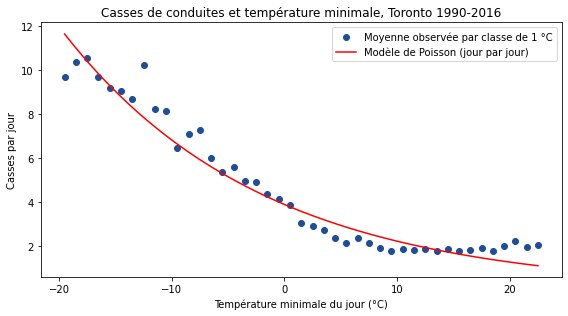

In [14]:
# add_constant ajoute une colonne de 1 : c'est le niveau de casses de départ (la constante du modèle).
X = sm.add_constant(tableau[["tmin", "annee"]])

# GLM = modèle linéaire généralisé. family=Poisson : on modélise un nombre de casses (entier positif).
# scale="X2" corrige les intervalles de confiance : les écarts réels entre jours sont plus grands que ceux que suppose le modèle de Poisson,
# et sans cette correction les intervalles seraient trop étroits.
modele = sm.GLM(tableau["casses"], X, family=sm.families.Poisson()).fit(
    cov_type="HAC", cov_kwds={"maxlags": 30})
print(modele.summary().tables[1])

# --- Lecture de l'effet du froid ---
b = modele.params["tmin"]            # coefficient de la température
ic = modele.conf_int().loc["tmin"]   # son intervalle de confiance à 95 %

# Le coefficient est sur une échelle logarithmique : exp(coefficient) - 1 donne un pourcentage.
# Il est négatif (plus chaud = moins de casses), donc on prend son opposé pour exprimer l'effet d'un degré de moins.
print(f"\nEffet : {(np.exp(-b)-1)*100:+.2f} % de casses par °C de moins "
      f"(IC 95 % : {(np.exp(-ic[1])-1)*100:+.2f} à {(np.exp(-ic[0])-1)*100:+.2f} %)")

# --- Graphique : moyennes observées par classe de température + courbe du modèle ---
# 9 800 points seraient illisibles : on affiche la moyenne de casses par jour pour chaque classe de 1 °C.
temp_points = []
casses_points = []
for t in sorted(tableau["classe"].unique()):
    jours_classe = tableau[tableau["classe"] == t]    # les jours de cette classe
    if len(jours_classe) >= 30:                       # on masque les classes très rares (affichage seulement)
        temp_points.append(t + 0.5)                   # milieu de la classe
        casses_points.append(jours_classe["casses"].mean())

# Courbe du modèle : exp(constante + coefficient_tmin × température + coefficient_annee × année moyenne)
t_ligne = np.linspace(min(temp_points), max(temp_points), 100)
courbe = np.exp(modele.params["const"] + b * t_ligne
                + modele.params["annee"] * tableau["annee"].mean())

fig, ax = plt.subplots(figsize=(8, 4.5))
ax.scatter(temp_points, casses_points, color="#1f4e99", label="Moyenne observée par classe de 1 °C")
ax.plot(t_ligne, courbe, "r-", label="Modèle de Poisson (jour par jour)")
ax.set_xlabel("Température minimale du jour (°C)")
ax.set_ylabel("Casses par jour")
ax.set_title("Casses de conduites et température minimale, Toronto 1990-2016")
ax.legend()
plt.tight_layout()
plt.show()

### Conclusion
L'effet reste de **+5,79 % de casses par °C de moins**, mais son intervalle de confiance à 95 % passe de **+5,62 / +5,97 %** à **+5,41 / +6,17 %**, soit environ deux fois plus large. L'effet du froid reste très significatif : même en tenant compte de la ressemblance entre jours voisins, il est très peu probable qu'il soit nul. Le même raisonnement vaut pour les intervalles de la section 7.

## 9. Conclusion générale

**Ce que montrent les données de Toronto (1990-2016, environ 35 000 casses).** Avec deux méthodes différentes, le résultat est le même : plus la température minimale est basse, plus il y a de casses.
- **Méthode 1 (celle de mon stage, par classes de température) :** taux de casse = 4,76 − 0,217 × température minimale, avec R² = 0,84 et p = 1,6 × 10⁻¹⁶ (40 classes gardées sur 54). Chaque degré de moins ajoute environ 0,22 casse par jour sur le réseau.
- **Méthode 2 (régression de Poisson jour par jour) :** **+5,79 % de casses par °C de moins** (IC 95 % : +5,62 à +5,97 %) (avant correction, voir section 8), soit environ 76 % de casses en plus pour 10 °C de moins. À température égale, le nombre de casses baisse d'environ 2 % par an.
- **Comparaison :** exprimée en pourcentage, la méthode 1 donne environ +4,5 % par °C de moins. Les deux méthodes concordent sur l'ordre de grandeur.

**Décalage.** Le résultat de la méthode 1 est stable quel que soit le décalage entre 0 et 7 jours (R² entre 0,83 et 0,84). Avec le Poisson, l'AIC est le plus bas pour la température d'il y a **3 jours** (49 845 contre 50 490 pour le jour même) : les casses sont mieux expliquées par le froid de quelques jours plus tôt. Je ne peux pas distinguer un vrai retard physique d'un décalage entre la casse et sa date d'enregistrement.

**Froid ou saison.** En comparant des jours d'un même mois, l'effet du froid passe de +5,79 % à +3,02 % par °C de moins : environ la moitié du lien vient de la saison, mais le froid garde un effet propre significatif.

### Limites
- Il s'agit de corrélations, pas de causes. Le fichier de Toronto ne contient ni matériau ni diamètre, alors que ces facteurs jouent beaucoup : l'âge des conduites, le sol et la pression ne sont pas pris en compte non plus.
- ERA5 est une réanalyse lissée (maille d'environ 30 km) : ses températures minimales sont plus douces que celles d'une station, et le « jour » d'ERA5 est un jour en heure UTC.
- Les jours ne sont pas indépendants (corrélation des écarts du Poisson de 0,453 à 1 jour). Les estimations restent valables, mais leurs intervalles de confiance sont plus larges que ceux calculés au départ (section 8)
- Les résultats concernent Toronto : ils ne sont pas transposables tels quels à un autre réseau.

### Pistes
- Appliquer la méthode à un réseau où le matériau et le diamètre sont connus, et séparer les conduites par catégorie.
- Ajouter d'autres variables : précipitations, humidité du sol (ERA5-Land), amplitude thermique, cycles de gel et dégel.
- Comparer ERA5 avec les relevés d'une station météo proche.
- Passer de l'échelle du réseau à celle du tronçon, pour estimer un risque par conduite.